# Pair 2 · Detecting attacks without labels (anomaly detection)
**HoneyBadger project, objective 2** · Siwar & Shayma

This notebook follows the four validation points: business understanding, data understanding, data preparation, and modeling with evaluation.

**How to run in Google Colab:** *Runtime → Run all* on a CPU runtime. Put `Train_data.csv` and `Test_data.csv` next to the notebook (drag them into the *Files* panel). Inside the repository, the CSVs go in the `data/` folder instead, and every output is written to `results/`. If they are missing, the notebook tries to download them from Kaggle, then asks you to upload them. A full run takes under a minute.

## 1. Business understanding

**Context.** HoneyBadger records every SSH and HTTP interaction with its fake services. Nobody labels these events as "attack" or "normal". Supervised models (objective 1) need such labels, so they cannot be trained directly on the honeypot's own data.

**Problem.** Can we detect attacks *without* attack labels, by learning what normal traffic looks like and flagging anything that does not fit?

**Objective.** Train models on **normal traffic only** (novelty detection). Each model gives every connection an *anomaly score*; connections whose score is above a threshold are flagged as attacks. The attack labels in the dataset are used **only to evaluate** the models, never to train them.

**What matters for the business**

| Error | Meaning | Cost |
|---|---|---|
| Missed attack (false negative) | An attack looks normal to the model | High: the attack goes unnoticed |
| False alarm (false positive) | Normal traffic looks unusual | Medium: wastes analyst time; too many and the alerts get ignored |

An alert system is only usable if false alarms stay rare, so the team fixes a **false-alarm budget of 1%** of normal traffic and asks how many attacks are caught within it.

**Metrics.** **Recall at a 1% false-alarm rate** is the main metric. **ROC-AUC** and **PR-AUC** measure how well the scores separate attacks from normal traffic at every threshold. At the chosen threshold we also report precision, F1, false alarms and missed attacks.

**Success criteria.** Separate attacks from normal traffic far better than chance (ROC-AUC well above 0.5), and catch most attacks while staying close to the 1% false-alarm budget. A supervised random forest trained *with* labels is shown as a reference for the best achievable result.

In [1]:
import hashlib
import io
import os
import time
import zipfile
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

SEED = 42
FALSE_ALARM_BUDGET = 0.01                              # 1% of normal traffic may be flagged
DATASET = 'sampadab17/network-intrusion-detection'
DATASET_PAGE = f'https://www.kaggle.com/datasets/{DATASET}'
DOWNLOAD_URL = os.environ.get('HB_DATASET_URL', f'https://www.kaggle.com/api/v1/datasets/download/{DATASET}')
EXPECTED_FILES = {
    'Train_data.csv': ('1e40eb667611ab507870fc5b5ef0a844201ec094915d78d79f4665937e43b07a', 2_875_560),
    'Test_data.csv': ('a58db8c605e58411f6432dd9ab2fe10e1d768f058f5453e9e279788c7219caf8', 2_416_180),
}
# Folder layout in the repository: notebooks/ (this file), data/ (the two CSVs), results/ (outputs).
# Outside the repository (for example in Colab), the CSVs and predictions stay next to the notebook.
REPO_ROOT = next((p for p in [Path('.'), Path('..')] if (p / 'scripts' / 'run_analysis.py').exists()), None)
DATA_DIR = REPO_ROOT / 'data' if REPO_ROOT else Path('.')
RESULTS_DIR = (REPO_ROOT or Path('.')) / 'results'
PREDICTIONS_DIR = RESULTS_DIR / 'predictions' if REPO_ROOT else Path('.')
for folder in (DATA_DIR, RESULTS_DIR, PREDICTIONS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
PREDICTIONS_FILE = PREDICTIONS_DIR / 'pair2_predictions.csv'
CLASSES = ['normal', 'anomaly']                       # anomaly = positive class (1)
CLASS_COLORS = {'normal': '#2a78d6', 'anomaly': '#eb6834'}
MODEL_STYLES = {'Isolation Forest': ('#2a78d6', '-'),
                'One-Class SVM': ('#eb6834', '--'),
                'Local Outlier Factor': ('#1baf7a', ':')}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True})
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print(f'pandas {pd.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | Colab: {IN_COLAB}')

pandas 3.1.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | Colab: False


### Load the data
Order of attempts: CSVs next to the notebook → Kaggle download → `kagglehub` → manual upload in Colab. Each file is then checked against its SHA-256 checksum, so the whole group analyses exactly the same data.

In [2]:
def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()


def save_new_file(name, data):
    target = DATA_DIR / name
    if target.exists():
        return
    tmp = target.with_name(f'{name}.part')
    tmp.write_bytes(data)
    tmp.replace(target)


def from_kaggle_zip(names):
    request = Request(DOWNLOAD_URL, headers={'User-Agent': 'honeybadger-notebook'})
    with urlopen(request, timeout=120) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    members = {Path(member).name: member for member in archive.namelist()}
    for name in names:
        save_new_file(name, archive.read(members[name]))


def from_kagglehub(names):
    import kagglehub
    folder = Path(kagglehub.dataset_download(DATASET))
    for name in names:
        save_new_file(name, next(folder.rglob(name)).read_bytes())


def from_colab_upload(names):
    if not IN_COLAB:
        raise RuntimeError('manual upload is only available in Colab')
    from google.colab import files
    print('Upload these files from the Kaggle download:', ', '.join(names))
    uploaded = files.upload()
    for name in names:
        if name in uploaded:
            save_new_file(name, uploaded[name])


def missing_files():
    return [name for name in EXPECTED_FILES if not (DATA_DIR / name).exists()]


for source in (from_kaggle_zip, from_kagglehub, from_colab_upload):
    if not missing_files():
        break
    try:
        source(missing_files())
        print(f'{source.__name__}: ok')
    except Exception as error:
        print(f'{source.__name__}: not available ({type(error).__name__}: {error})')
if missing_files():
    raise FileNotFoundError(f'Missing {missing_files()}. Download them from {DATASET_PAGE} and put them in the folder {DATA_DIR}.')
for name, (expected_sha, expected_size) in EXPECTED_FILES.items():
    actual_sha, actual_size = sha256_of(DATA_DIR / name), (DATA_DIR / name).stat().st_size
    if (actual_sha, actual_size) != (expected_sha, expected_size):
        raise ValueError(f'{name} differs from the reviewed Kaggle file (size {actual_size:,}, sha256 {actual_sha}).')
    print(f'{name}: {actual_size:,} bytes, sha256 verified')

train = pd.read_csv(DATA_DIR / 'Train_data.csv')
test = pd.read_csv(DATA_DIR / 'Test_data.csv')
features = [c for c in train.columns if c != 'class']
assert features == list(test.columns)
test = test.astype(train[features].dtypes.to_dict())

Train_data.csv: 2,875,560 bytes, sha256 verified
Test_data.csv: 2,416,180 bytes, sha256 verified


## 2. Data understanding

### 2.1 Size and structure

In [3]:
categorical = train[features].select_dtypes(exclude='number').columns.tolist()
numeric = [c for c in features if c not in categorical]
print(f'Train_data.csv: {train.shape[0]:,} rows x {train.shape[1]} columns (41 features + label "class")')
print(f'Test_data.csv:  {test.shape[0]:,} rows x {test.shape[1]} columns (same 41 features, no label)')
print(f'{len(categorical)} categorical features: {categorical}; {len(numeric)} numeric features')
print('Missing values in train / test:', int(train.isna().sum().sum()), '/', int(test.isna().sum().sum()))
print('Smallest numeric value in train:', train[numeric].min().min(), '(no negatives, so log1p is safe)')
for column in categorical:
    print(f'{column}: {train[column].nunique()} distinct values')

Train_data.csv: 25,192 rows x 42 columns (41 features + label "class")
Test_data.csv:  22,544 rows x 41 columns (same 41 features, no label)
3 categorical features: ['protocol_type', 'service', 'flag']; 38 numeric features
Missing values in train / test: 0 / 0
Smallest numeric value in train: 0.0 (no negatives, so log1p is safe)
protocol_type: 3 distinct values
service: 66 distinct values
flag: 11 distinct values


### 2.2 What the features mean
One row is one network connection. The 41 features come from the KDD intrusion-detection format and fall into four groups:

| Group | Features | Meaning |
|---|---|---|
| Basic | `duration`, `protocol_type`, `service`, `flag`, `src_bytes`, `dst_bytes`, `land`, `wrong_fragment`, `urgent` | Connection length, protocol (tcp/udp/icmp), target service (http, ssh, …), TCP status flag, bytes sent each way, malformed-packet indicators |
| Content | `hot`, `num_failed_logins`, `logged_in`, `num_compromised`, `root_shell`, `su_attempted`, `num_root`, `num_file_creations`, `num_shells`, `num_access_files`, `num_outbound_cmds`, `is_host_login`, `is_guest_login` | What happened inside the session: failed logins, successful login, root access, files created |
| Time-based traffic (last 2 seconds) | `count`, `srv_count`, `serror_rate`, `srv_serror_rate`, `rerror_rate`, `srv_rerror_rate`, `same_srv_rate`, `diff_srv_rate`, `srv_diff_host_rate` | How many recent connections went to the same host or service, and what share had SYN (`serror`) or REJ (`rerror`) errors |
| Host-based (last 100 connections) | `dst_host_count`, `dst_host_srv_count`, `dst_host_same_srv_rate`, `dst_host_diff_srv_rate`, `dst_host_same_src_port_rate`, `dst_host_srv_diff_host_rate`, `dst_host_serror_rate`, `dst_host_srv_serror_rate`, `dst_host_rerror_rate`, `dst_host_srv_rerror_rate` | The same statistics over a longer window, which catches slow scans |

The label `class` is `normal` or `anomaly`. The dataset does not give the attack type.

### 2.3 Class distribution, and why it shapes the method

,rows,share
class,,
normal,13449,0.534
anomaly,11743,0.466


Most skewed numeric features (skewness): {'urgent': 158.7, 'src_bytes': 157.6, 'land': 112.2, 'num_root': 62.3, 'num_compromised': 62.2}


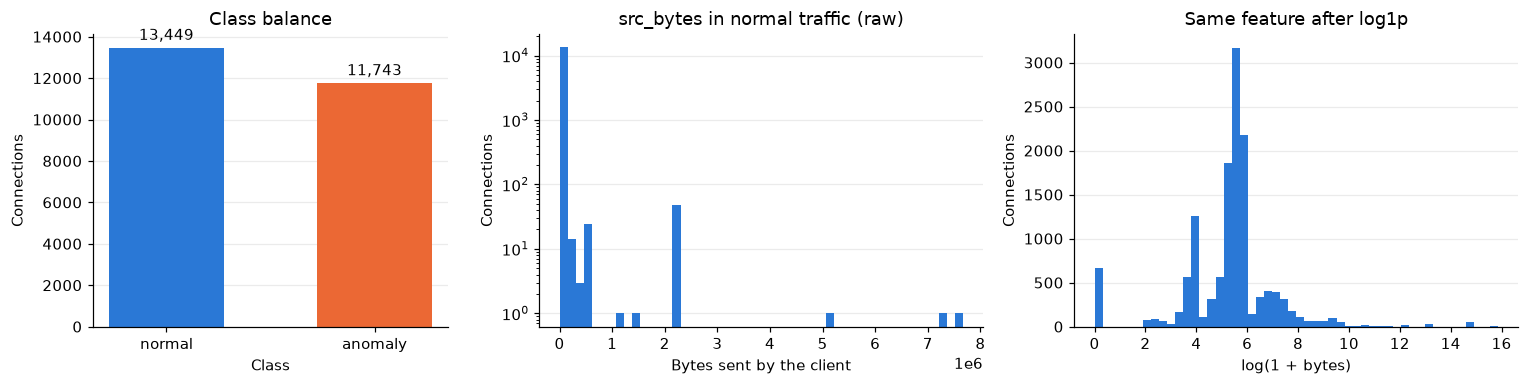

In [4]:
balance = train['class'].value_counts().reindex(CLASSES)
display(balance.to_frame('rows').assign(share=(balance / balance.sum()).round(3)))
normal_rows = train[train['class'] == 'normal']
skew = train[numeric].skew().sort_values(ascending=False)
print('Most skewed numeric features (skewness):', skew.head(5).round(1).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), gridspec_kw={'width_ratios': [0.8, 1, 1]})
axes[0].bar(balance.index, balance.values, color=[CLASS_COLORS[c] for c in balance.index], width=0.55)
for x, value in enumerate(balance.values):
    axes[0].annotate(f'{value:,}', (x, value), ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')
axes[0].set(title='Class balance', xlabel='Class', ylabel='Connections')
axes[1].hist(normal_rows['src_bytes'], bins=50, color=CLASS_COLORS['normal'])
axes[1].set(title='src_bytes in normal traffic (raw)', xlabel='Bytes sent by the client', ylabel='Connections', yscale='log')
axes[2].hist(np.log1p(normal_rows['src_bytes']), bins=50, color=CLASS_COLORS['normal'])
axes[2].set(title='Same feature after log1p', xlabel='log(1 + bytes)', ylabel='Connections')
for ax in axes:
    ax.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()

**Reading the charts.** Attacks make up about 47% of the labeled rows. Anomaly-detection models assume anomalies are *rare*; trained on this mixed data, they would learn attacks as part of "normal". That is why this notebook trains on **normal rows only** and treats every attack as something new. In HoneyBadger, the equivalent would be a period of traffic known to be clean.

The raw byte counts are extremely skewed: most connections send little, a few send millions of bytes. These models compare connections by distance or density, so one huge value would dominate. The log transform spreads the values into a usable range.

## 3. Data preparation

| Step | Decision | Why |
|---|---|---|
| Missing values | None to treat | Section 2.1 found 0 missing cells |
| Constant columns | Drop `num_outbound_cmds` and `is_host_login` | One value only, so no information |
| Validation split | The same grouped 80/20 split as the other notebooks | Results are comparable across the group; identical feature vectors never span the two partitions |
| Training data | **Normal rows of the training partition only** | Novelty detection: the model learns normal behaviour and must never see an attack |
| Calibration set | 20% of those normal rows, kept aside | The alert threshold is set on normal rows the model did not train on, so it is not biased |
| Categorical encoding | One-hot encoding; values seen in under 1% of normal rows are grouped as "infrequent", and unseen values join that group | Keeps the number of columns small for distance-based models. A service normal traffic rarely uses is itself a useful signal |
| Skew | `log1p` on every numeric feature | Byte counts and durations are extremely skewed (section 2.3); counts and rates are left in a comparable range |
| Scaling | Standard scaling (mean 0, standard deviation 1), fitted on normal training rows | Distance and density depend on scale, so no feature should dominate because of its units |
| Class imbalance | Not applicable to training | Only one class (normal) is used for training; attack labels are used for evaluation only |
| Feature selection | Section 4.6 compares all features with a HoneyBadger-compatible subset | Tests whether the method could run on features the honeypot can compute |

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

constant = [c for c in features if train[c].nunique() == 1]
model_features = [c for c in features if c not in constant]
categorical = [c for c in categorical if c in model_features]
numeric = [c for c in model_features if c not in categorical]
print('Dropped constant columns:', constant)

X = train[model_features]
y = (train['class'] == 'anomaly').astype(int).to_numpy()   # 1 = anomaly; used for evaluation only


def vector_keys(frame):
    return frame[features].astype(str).agg('|'.join, axis=1)


codes, _ = pd.factorize(pd.concat([vector_keys(train), vector_keys(test)], ignore_index=True))
train_ids, test_ids = codes[:len(train)], codes[len(train):]


def grouped_stratified_folds(groups, labels, n_folds=5, seed=SEED):
    # Fold number per row; whole groups stay in one fold; shuffled within each class with a fixed seed.
    frame = pd.DataFrame({'group': groups, 'label': np.asarray(labels)})
    group_label = frame.groupby('group')['label'].agg(lambda s: sorted(s.mode())[0])
    group_size = frame.groupby('group').size()
    rng = np.random.default_rng(seed)
    group_fold = {}
    for label in sorted(group_label.unique()):
        members = group_label.index[group_label == label].to_numpy()
        members = members[rng.permutation(len(members))]
        sizes = group_size.loc[members].to_numpy()
        starts = np.cumsum(sizes) - sizes
        group_fold.update(zip(members, starts * n_folds // sizes.sum()))
    return frame['group'].map(group_fold).to_numpy()


folds = grouped_stratified_folds(train_ids, y)
fit_idx, val_idx = np.flatnonzero(folds != 0), np.flatnonzero(folds == 0)
X_val, y_val = X.iloc[val_idx], y[val_idx]
assert not set(train_ids[fit_idx]) & set(train_ids[val_idx]), 'a feature vector is in both partitions'

# Normal rows of the training partition, split by group into model-fit (80%) and threshold-calibration (20%).
normal_idx = fit_idx[y[fit_idx] == 0]
calib_fold = grouped_stratified_folds(train_ids[normal_idx], np.zeros(len(normal_idx)), seed=SEED + 2)
fit_normal_idx, calib_idx = normal_idx[calib_fold != 0], normal_idx[calib_fold == 0]
X_fit_normal, X_calib = X.iloc[fit_normal_idx], X.iloc[calib_idx]
assert y[fit_normal_idx].sum() == 0 and y[calib_idx].sum() == 0, 'training and calibration must contain no attacks'

display(pd.DataFrame({'rows': [len(fit_normal_idx), len(calib_idx), len(val_idx)],
                      'attacks': [0, 0, int(y_val.sum())],
                      'used for': ['fitting the models', 'setting the alert threshold', 'evaluation only']},
                     index=['normal training rows', 'normal calibration rows', 'validation partition']))


def make_preprocessor(cat_cols, num_cols):
    scale = Pipeline([('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')), ('scale', StandardScaler())])
    encode = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.01)
    return ColumnTransformer([('cat', encode, cat_cols), ('num', scale, num_cols)], sparse_threshold=0)


prep = make_preprocessor(categorical, numeric).fit(X_fit_normal)
Z_fit, Z_calib, Z_val = prep.transform(X_fit_normal), prep.transform(X_calib), prep.transform(X_val)
encoded = [n.split('__', 1)[1] for n in prep.get_feature_names_out()]
print(f'Prepared matrix: {Z_fit.shape[1]} columns ({sum(n.split("_")[0] in ("protocol", "service", "flag") for n in encoded)} one-hot + {len(numeric)} numeric)')
print('Service values kept as their own column:', sorted(n.replace('service_', '') for n in encoded if n.startswith('service_')))

Dropped constant columns: ['num_outbound_cmds', 'is_host_login']


,rows,attacks,used for
normal training rows,8607,0,fitting the models
normal calibration rows,2152,0,setting the alert threshold
validation partition,5039,2349,evaluation only


Prepared matrix: 51 columns (15 one-hot + 36 numeric)
Service values kept as their own column: ['domain_u', 'ftp', 'ftp_data', 'http', 'infrequent_sklearn', 'other', 'private', 'smtp', 'telnet']


## 4. Modeling

### 4.1 Models and why they were chosen

| Model | How it scores a connection | Why it fits this objective |
|---|---|---|
| **Isolation Forest** | Random trees split the data; unusual points are isolated in few splits | Fast on large tabular data, few assumptions, no distance computation |
| **One-Class SVM** (RBF kernel) | Learns a boundary around normal traffic; distance outside it is the score | Can draw a flexible, non-linear boundary. Training cost grows quickly with rows, so it is fitted on a random sample of 5,000 normal rows |
| **Local Outlier Factor** (novelty mode) | Compares a point's local density with that of its nearest normal neighbours | Detects points in unusually sparse regions; a different, density-based view |
| Random score | Random numbers | The no-skill baseline: ROC-AUC 0.5 |
| Random forest *with labels* | Supervised model from objective 1 | Reference only: shows the best achievable result when labels exist |

The hyperparameters were fixed in advance from common defaults: 200 trees for Isolation Forest, `nu = 0.01` for One-Class SVM (about 1% of clean training rows may fall outside the boundary, matching the false-alarm budget), and 20 neighbours for LOF. Section 4.5 checks that the results are not fragile to these choices.

**Threshold.** For each model, the alert threshold is the 99th percentile of its scores on the *normal calibration rows*, so about 1% of normal traffic is expected to be flagged. No attack label is used to set it.

In [6]:
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

rng = np.random.default_rng(SEED)
svm_sample = rng.choice(len(Z_fit), size=min(5000, len(Z_fit)), replace=False)
detectors = {'Isolation Forest': IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1),
             'One-Class SVM': OneClassSVM(kernel='rbf', gamma='scale', nu=0.01),
             'Local Outlier Factor': LocalOutlierFactor(n_neighbors=20, novelty=True)}


def anomaly_score(model, Z):
    return -model.score_samples(Z)    # higher = more unusual


fit_seconds, val_scores, thresholds = {}, {}, {}
for name, model in detectors.items():
    start = time.time()
    model.fit(Z_fit[svm_sample] if name == 'One-Class SVM' else Z_fit)
    fit_seconds[name] = time.time() - start
    thresholds[name] = np.quantile(anomaly_score(model, Z_calib), 1 - FALSE_ALARM_BUDGET)
    val_scores[name] = anomaly_score(model, Z_val)
val_scores['Random score'] = np.random.default_rng(SEED).random(len(y_val))
thresholds['Random score'] = 1 - FALSE_ALARM_BUDGET

reference = Pipeline([('prep', ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), categorical)],
                                                 remainder='passthrough')),
                      ('model', RandomForestClassifier(n_estimators=150, max_features=0.3, random_state=SEED, n_jobs=-1))])
reference.fit(X.iloc[fit_idx], y[fit_idx])
val_scores['Random forest (with labels)'] = reference.predict_proba(X_val)[:, 1]
thresholds['Random forest (with labels)'] = 0.5


def recall_at_fpr(y_true, score, target):
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(np.interp(target, fpr, tpr))


def evaluate(y_true, score, threshold):
    y_pred = (score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {'ROC-AUC': roc_auc_score(y_true, score), 'PR-AUC': average_precision_score(y_true, score),
            'recall at 1% FPR': recall_at_fpr(y_true, score, 0.01),
            'false-alarm rate': fp / (fp + tn), 'recall': tp / (tp + fn),
            'precision': precision_score(y_true, y_pred, zero_division=0), 'F1': f1_score(y_true, y_pred, zero_division=0),
            'false alarms': int(fp), 'missed attacks': int(fn), 'attacks caught': int(tp), 'normal passed': int(tn)}


results = pd.DataFrame({name: evaluate(y_val, score, thresholds[name]) for name, score in val_scores.items()}).T
counts = ['false alarms', 'missed attacks', 'attacks caught', 'normal passed']
results[counts] = results[counts].astype(int)
rates = [c for c in results.columns if c not in counts]
results[rates] = results[rates].astype(float).round(4)
results['fit time (s)'] = pd.Series(fit_seconds).round(2)
display(results)
unsupervised = list(detectors)
best_name = results.loc[unsupervised, 'recall at 1% FPR'].idxmax()
print(f'Best unsupervised model by recall at a 1% false-alarm rate: {best_name}')
ranked = results.loc[unsupervised].sort_values('recall at 1% FPR', ascending=False)
first, second = ranked.index[:2]
gap = ranked.loc[first, 'recall at 1% FPR'] - ranked.loc[second, 'recall at 1% FPR']
if gap < 0.02:
    print(f'This is a near tie: {second} is only {gap:.3f} behind on this metric. At its own alert threshold, '
          f'{second} catches {int(results.loc[second, "attacks caught"]):,} attacks with '
          f'{int(results.loc[second, "false alarms"]):,} false alarms, against '
          f'{int(results.loc[first, "attacks caught"]):,} and {int(results.loc[first, "false alarms"]):,} for {first}.')

,ROC-AUC,PR-AUC,recall at 1% FPR,false-alarm rate,recall,precision,F1,false alarms,missed attacks,attacks caught,normal passed,fit time (s)
Isolation Forest,0.9825,0.9815,0.8323,0.0119,0.8399,0.9840,0.9063,32,376,1973,2658,0.54
One-Class SVM,0.9769,0.9611,0.8429,0.0078,0.7871,0.9888,0.8765,21,500,1849,2669,0.04
Local Outlier Factor,0.9319,0.8717,0.1958,0.0078,0.1145,0.9276,0.2039,21,2080,269,2669,0.18
Random score,0.5030,0.4679,0.0085,0.0119,0.0119,0.4667,0.0232,32,2321,28,2658,NaN
Random forest (with labels),1.0000,1.0000,0.9996,0.0000,0.9957,1.0000,0.9979,0,10,2339,2690,NaN


Best unsupervised model by recall at a 1% false-alarm rate: One-Class SVM
This is a near tie: Isolation Forest is only 0.011 behind on this metric. At its own alert threshold, Isolation Forest catches 1,973 attacks with 32 false alarms, against 1,849 and 21 for One-Class SVM.


### 4.2 Results in pictures
The histograms show how each model scores normal and attack connections in the validation partition; the dashed line is its alert threshold. Good separation means the two colours sit on opposite sides of the line.

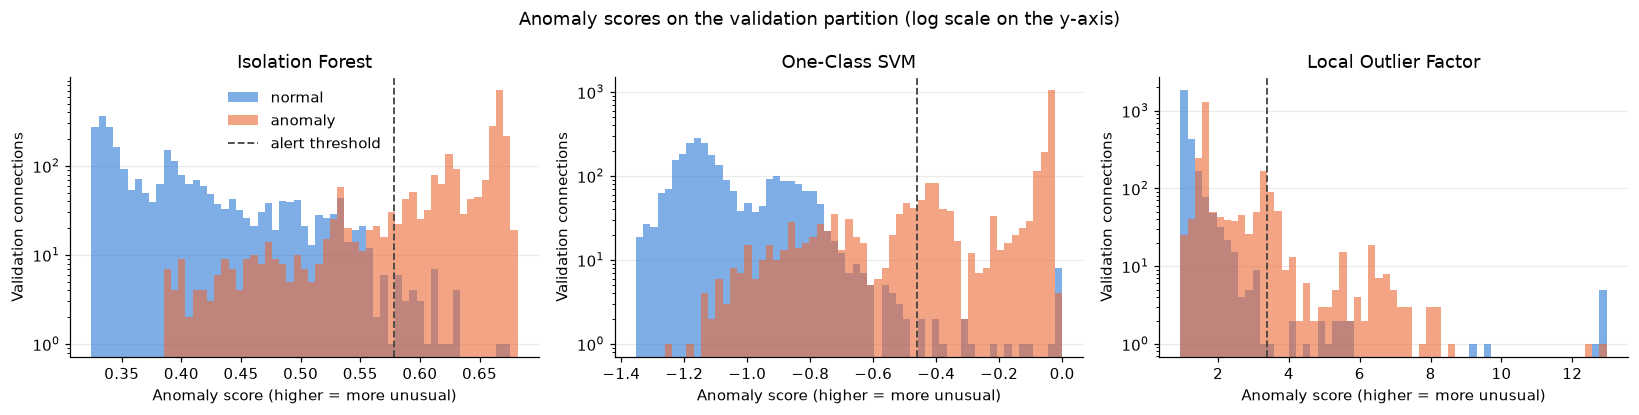

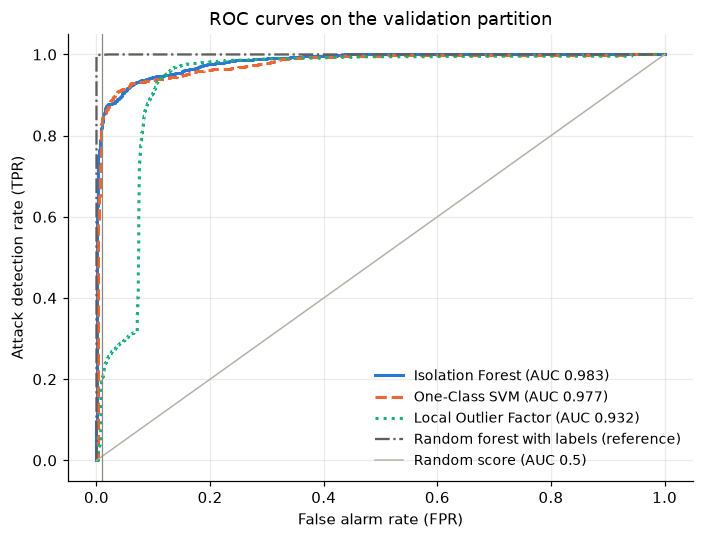

The thin vertical line marks the 1% false-alarm budget.


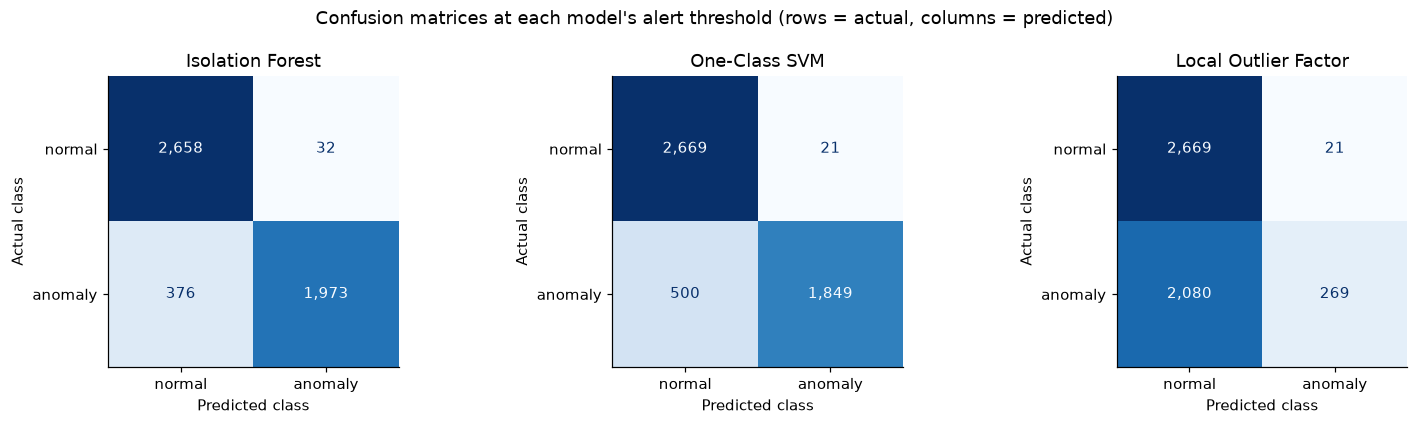

Plain-language result: the validation partition holds 2,349 attacks and 2,690 normal connections.
Without ever seeing an attack, the One-Class SVM caught 1,849 attacks and missed 500 (recall 78.7%), with 21 false alarms (0.8% of normal traffic).
With labels, the supervised random forest caught 2,339 attacks. The gap is the price of having no labels.


In [7]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, name in zip(axes, unsupervised):
    score = val_scores[name]
    low, high = np.quantile(score, [0.001, 0.999])
    bins = np.linspace(low, high, 60)
    for label, cls in enumerate(CLASSES):
        ax.hist(np.clip(score[y_val == label], low, high), bins=bins, alpha=0.6, color=CLASS_COLORS[cls], label=cls)
    ax.axvline(thresholds[name], color='#444441', linestyle='--', linewidth=1.2, label='alert threshold')
    ax.set(title=name, xlabel='Anomaly score (higher = more unusual)', ylabel='Validation connections', yscale='log')
    ax.grid(axis='x', visible=False)
axes[0].legend(frameon=False)
fig.suptitle('Anomaly scores on the validation partition (log scale on the y-axis)')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5))
for name, (color, style) in MODEL_STYLES.items():
    fpr, tpr, _ = roc_curve(y_val, val_scores[name])
    ax.plot(fpr, tpr, color=color, linestyle=style, linewidth=2, label=f"{name} (AUC {results.loc[name, 'ROC-AUC']:.3f})")
fpr, tpr, _ = roc_curve(y_val, val_scores['Random forest (with labels)'])
ax.plot(fpr, tpr, color='#5F5E5A', linestyle='-.', linewidth=1.5, label='Random forest with labels (reference)')
ax.plot([0, 1], [0, 1], color='#B4B2A9', linewidth=1, label='Random score (AUC 0.5)')
ax.axvline(FALSE_ALARM_BUDGET, color='#888780', linewidth=0.8)
ax.set(title='ROC curves on the validation partition', xlabel='False alarm rate (FPR)', ylabel='Attack detection rate (TPR)')
ax.legend(frameon=False, loc='lower right', fontsize=9)
fig.tight_layout()
plt.show()
print('The thin vertical line marks the 1% false-alarm budget.')

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, name in zip(axes, unsupervised):
    y_pred = (val_scores[name] >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_val, y_pred, labels=[0, 1], display_labels=CLASSES,
                                            cmap='Blues', colorbar=False, ax=ax, values_format=',')
    ax.set(title=name, xlabel='Predicted class', ylabel='Actual class')
    ax.grid(False)
fig.suptitle('Confusion matrices at each model\'s alert threshold (rows = actual, columns = predicted)')
fig.tight_layout()
plt.show()

r = results.loc[best_name]
n_attacks, n_normal = int(r['attacks caught'] + r['missed attacks']), int(r['normal passed'] + r['false alarms'])
print(f'Plain-language result: the validation partition holds {n_attacks:,} attacks and {n_normal:,} normal connections.')
print(f'Without ever seeing an attack, the {best_name} caught {int(r["attacks caught"]):,} attacks and missed '
      f'{int(r["missed attacks"]):,} (recall {r["recall"]:.1%}), with {int(r["false alarms"]):,} false alarms '
      f'({r["false-alarm rate"]:.1%} of normal traffic).')
ref = results.loc['Random forest (with labels)']
print(f'With labels, the supervised random forest caught {int(ref["attacks caught"]):,} attacks. '
      f'The gap is the price of having no labels.')

### 4.3 Choosing the false-alarm budget
The 1% budget is a business choice. The table shows what the best model would do with other budgets: each threshold is again set from the normal calibration rows only, then checked on the validation partition.

,actual false-alarm rate,recall,precision,false alarms,missed attacks
budget (share of normal flagged),,,,,
0.5%,0.0059,0.6556,0.9897,16,809
1.0%,0.0078,0.7871,0.9888,21,500
2.0%,0.0257,0.8863,0.9679,69,267
5.0%,0.0599,0.9259,0.9311,161,174
10.0%,0.1126,0.9400,0.8793,303,141


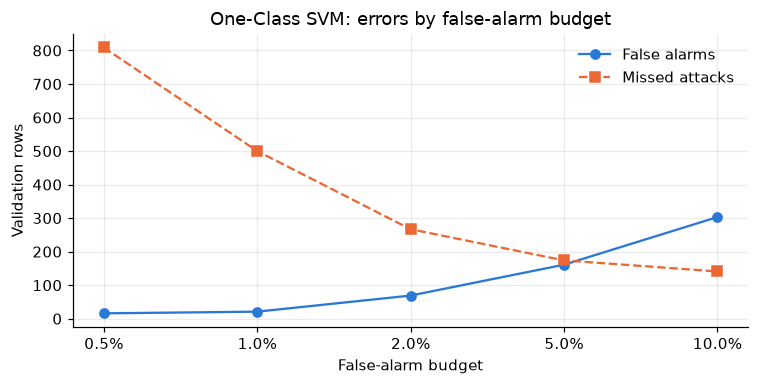

The "actual false-alarm rate" column checks that a threshold set on normal calibration rows holds on new data.


In [8]:
best = detectors[best_name]
calib_scores = anomaly_score(best, Z_calib)
rows = []
for budget in [0.005, 0.01, 0.02, 0.05, 0.10]:
    threshold = np.quantile(calib_scores, 1 - budget)
    m = evaluate(y_val, val_scores[best_name], threshold)
    rows.append({'budget (share of normal flagged)': f'{budget:.1%}', 'actual false-alarm rate': round(m['false-alarm rate'], 4),
                 'recall': round(m['recall'], 4), 'precision': round(m['precision'], 4),
                 'false alarms': m['false alarms'], 'missed attacks': m['missed attacks']})
budget_table = pd.DataFrame(rows).set_index('budget (share of normal flagged)')
display(budget_table)

fig, ax = plt.subplots(figsize=(7, 3.6))
x = np.arange(len(budget_table))
ax.plot(x, budget_table['false alarms'], color='#2a78d6', marker='o', linestyle='-', label='False alarms')
ax.plot(x, budget_table['missed attacks'], color='#eb6834', marker='s', linestyle='--', label='Missed attacks')
ax.set_xticks(x, budget_table.index)
ax.set(title=f'{best_name}: errors by false-alarm budget', xlabel='False-alarm budget', ylabel='Validation rows')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
print('The "actual false-alarm rate" column checks that a threshold set on normal calibration rows holds on new data.')

### 4.4 Which attacks are missed?
A model can score well overall and still be blind to one kind of attack. The `flag` feature describes how a TCP connection ended and roughly separates attack styles: `S0` means a connection request got no reply (typical of SYN floods), `REJ` means it was refused (typical of scans), and `SF` is a normal, completed connection.

In [9]:
val_attacks = X_val[y_val == 1]
by_flag = {}
for name in unsupervised:
    missed = val_scores[name][y_val == 1] < thresholds[name]
    by_flag[name] = pd.Series(missed, index=val_attacks.index).groupby(val_attacks['flag']).mean()
flag_table = pd.DataFrame(by_flag)
flag_table.insert(0, 'attacks', val_attacks['flag'].value_counts())
flag_table = flag_table.sort_values('attacks', ascending=False).head(6)
print('Share of attacks MISSED, by TCP flag (validation partition):')
display(flag_table.round(3))

service_group = np.where(X_val['service'].isin(['ssh', 'http']), X_val['service'], 'other services')
rows = {}
for group in ['ssh', 'http', 'other services']:
    mask = service_group == group
    row = {'attacks': int(y_val[mask].sum()), 'normal': int((y_val[mask] == 0).sum())}
    for name in unsupervised:
        flagged = val_scores[name][mask] >= thresholds[name]
        row[f'{name}: recall'] = round(flagged[y_val[mask] == 1].mean(), 3) if y_val[mask].sum() else np.nan
        row[f'{name}: false alarms'] = int(flagged[y_val[mask] == 0].sum())
    rows[group] = row
print('Results by service:')
display(pd.DataFrame.from_dict(rows, orient='index'))

s0 = flag_table.loc['S0'] if 'S0' in flag_table.index else None
if s0 is not None:
    worst = s0[unsupervised].idxmax()
    print(f'S0 connections (no reply) make up {int(s0["attacks"]):,} validation attacks. '
          f'{worst} misses {s0[worst]:.0%} of them.')
print('SSH has no normal rows in this data, so SSH false alarms cannot be measured.')

Share of attacks MISSED, by TCP flag (validation partition):


,attacks,Isolation Forest,One-Class SVM,Local Outlier Factor
flag,,,,
S0,1340,0.000,0.001,1.000
SF,471,0.756,0.951,0.794
REJ,394,0.018,0.074,0.599
RSTR,79,0.127,0.253,0.962
RSTO,52,0.038,0.000,0.788
SH,9,0.000,0.000,1.000


Results by service:


,attacks,normal,Isolation Forest: recall,Isolation Forest: false alarms,One-Class SVM: recall,One-Class SVM: false alarms,Local Outlier Factor: recall,Local Outlier Factor: false alarms
ssh,6,0,1.000,0,0.833,0,0.167,0
http,89,1497,0.506,8,0.506,1,0.112,7
other services,2254,1193,0.853,24,0.798,20,0.114,14


S0 connections (no reply) make up 1,340 validation attacks. Local Outlier Factor misses 100% of them.
SSH has no normal rows in this data, so SSH false alarms cannot be measured.


**Interpretation.** Isolation Forest and One-Class SVM measure how *far* a connection is from normal traffic, so floods of unanswered connections stand out clearly. Local Outlier Factor measures density *relative to the nearest normal neighbours*: if the closest normal connections are themselves in a sparse region, an attack next to them gets an ordinary score. The table above shows the consequence for each kind of attack.

Isolation Forest and One-Class SVM miss mostly connections that completed normally (`SF`): they look like ordinary traffic, so a model that only knows normal behaviour has little to go on. Web (HTTP) attacks are mostly completed connections, which is why their HTTP recall is lower than for other services. The choice of detector matters as much as the threshold.

### 4.5 Sensitivity of the hyperparameters
The settings were fixed before evaluation. This check varies each one to see whether the conclusions depend on a lucky choice. It is not used to pick the settings: picking them on the validation labels would leak information the method is not supposed to have.

In [10]:
variants = {'Isolation Forest': ('trees', [100, 200, 400], lambda v: IsolationForest(n_estimators=v, random_state=SEED, n_jobs=-1)),
            'One-Class SVM': ('nu', [0.005, 0.01, 0.05], lambda v: OneClassSVM(kernel='rbf', gamma='scale', nu=v)),
            'Local Outlier Factor': ('neighbours', [10, 20, 50], lambda v: LocalOutlierFactor(n_neighbors=v, novelty=True))}
rows = []
for name, (param, values, build) in variants.items():
    for value in values:
        model = build(value).fit(Z_fit[svm_sample] if name == 'One-Class SVM' else Z_fit)
        threshold = np.quantile(anomaly_score(model, Z_calib), 1 - FALSE_ALARM_BUDGET)
        m = evaluate(y_val, anomaly_score(model, Z_val), threshold)
        rows.append({'model': name, 'setting': f'{param} = {value}', 'ROC-AUC': round(m['ROC-AUC'], 4),
                     'recall at 1% FPR': round(m['recall at 1% FPR'], 4), 'false-alarm rate': round(m['false-alarm rate'], 4),
                     'recall': round(m['recall'], 4)})
sensitivity = pd.DataFrame(rows).set_index(['model', 'setting'])
display(sensitivity)
spread = sensitivity.groupby(level='model')['recall at 1% FPR'].agg(['min', 'max']).round(3)
print('Range of recall at 1% FPR across the settings tried:')
display(spread)

ROC-AUC  recall at 1% FPR  \
model                setting                                      
Isolation Forest     trees = 100       0.9834            0.8480   
                     trees = 200       0.9825            0.8323   
                     trees = 400       0.9822            0.7986   
One-Class SVM        nu = 0.005        0.9769            0.8429   
                     nu = 0.01         0.9769            0.8429   
                     nu = 0.05         0.9764            0.7284   
Local Outlier Factor neighbours = 10   0.8879            0.1933   
                     neighbours = 20   0.9319            0.1958   
                     neighbours = 50   0.8832            0.0332   

                                      false-alarm rate  recall  
model                setting                                    
Isolation Forest     trees = 100                0.0112  0.8578  
                     trees = 200                0.0119  0.8399  
                     trees = 400                0.0112  0.8037  
One-Class SVM        nu = 0.005                 0.0078  0.7871  
                     nu = 0.01                  0.0078  0.7871  
                     nu = 0.05                  0.0108  0.7910  
Local Outlier Factor neighbours = 10            0.0067  0.1379  
                     neighbours = 20            0.0078  0.1145  
                     neighbours = 50            0.0104  0.0341

Range of recall at 1% FPR across the settings tried:


,min,max
model,,
Isolation Forest,0.799,0.848
Local Outlier Factor,0.033,0.196
One-Class SVM,0.728,0.843


### 4.6 Feature selection, and the HoneyBadger question
The best model is retrained on **HoneyBadger-compatible features** only: features whose idea the honeypot records or could derive from its event log (service, login outcome, connection counts over time). Bytes, durations, TCP flags and error rates are excluded because HoneyBadger does not capture them. This is an approximation: HoneyBadger would compute the counts per source IP, not exactly as the dataset does, and every SSH login it receives succeeds.

In [11]:
HONEYBADGER_FEATURES = ['service', 'num_failed_logins', 'logged_in', 'count', 'srv_count', 'same_srv_rate',
                        'diff_srv_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate',
                        'dst_host_diff_srv_rate']


def fresh_detector(name):
    return {'Isolation Forest': lambda: IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1),
            'One-Class SVM': lambda: OneClassSVM(kernel='rbf', gamma='scale', nu=0.01),
            'Local Outlier Factor': lambda: LocalOutlierFactor(n_neighbors=20, novelty=True)}[name]()


comparison = {}
for label, columns in [('All features', model_features), ('HoneyBadger-compatible', HONEYBADGER_FEATURES)]:
    cats = [c for c in categorical if c in columns]
    nums = [c for c in columns if c not in cats]
    p = make_preprocessor(cats, nums).fit(X_fit_normal[columns])
    z_fit = p.transform(X_fit_normal[columns])
    model = fresh_detector(best_name).fit(z_fit[svm_sample] if best_name == 'One-Class SVM' else z_fit)
    threshold = np.quantile(anomaly_score(model, p.transform(X_calib[columns])), 1 - FALSE_ALARM_BUDGET)
    m = evaluate(y_val, anomaly_score(model, p.transform(X_val[columns])), threshold)
    comparison[label] = {'features': len(columns), **{k: m[k] for k in ['ROC-AUC', 'recall at 1% FPR', 'false-alarm rate',
                                                                         'recall', 'false alarms', 'missed attacks']}}
comparison = pd.DataFrame(comparison).T
comparison[['features', 'false alarms', 'missed attacks']] = comparison[['features', 'false alarms', 'missed attacks']].astype(int)
display(comparison.round(4))
change = comparison.loc['HoneyBadger-compatible', 'recall at 1% FPR'] - comparison.loc['All features', 'recall at 1% FPR']
print(f'{best_name} with HoneyBadger-compatible features only: recall at 1% FPR changes by {change:+.4f}.')

,features,ROC-AUC,recall at 1% FPR,false-alarm rate,recall,false alarms,missed attacks
All features,39,0.9769,0.8429,0.0078,0.7871,21,500
HoneyBadger-compatible,11,0.9271,0.4593,0.0104,0.4798,28,1222


One-Class SVM with HoneyBadger-compatible features only: recall at 1% FPR changes by -0.3836.


## 5. Scores for the unlabeled test file
The best model is refitted on **all normal labeled rows** (except a 20% calibration set for the threshold), then scores every row of `Test_data.csv`. The test file has no labels, so no metric can be computed on it. The export keeps the original row order:

* `anomaly_score`: higher means more unusual.
* `predicted_class`: `anomaly` when the score is above the 1% threshold.
* `seen_in_training`: the identical feature vector occurs in `Train_data.csv`.

In [12]:
all_normal = np.flatnonzero(y == 0)
final_fold = grouped_stratified_folds(train_ids[all_normal], np.zeros(len(all_normal)), seed=SEED + 3)
final_fit, final_calib = all_normal[final_fold != 0], all_normal[final_fold == 0]
final_prep = make_preprocessor(categorical, numeric).fit(X.iloc[final_fit])
z_final = final_prep.transform(X.iloc[final_fit])
if best_name == 'One-Class SVM':
    z_final = z_final[np.random.default_rng(SEED).choice(len(z_final), size=min(5000, len(z_final)), replace=False)]
final_model = fresh_detector(best_name).fit(z_final)
final_threshold = np.quantile(anomaly_score(final_model, final_prep.transform(X.iloc[final_calib])), 1 - FALSE_ALARM_BUDGET)
test_score = anomaly_score(final_model, final_prep.transform(test[model_features]))

result = pd.DataFrame({'test_row': np.arange(len(test)), 'anomaly_score': test_score.round(6),
                       'predicted_class': np.where(test_score >= final_threshold, 'anomaly', 'normal'),
                       'seen_in_training': np.isin(test_ids, train_ids)})
result.to_csv(PREDICTIONS_FILE, index=False)
check = pd.read_csv(PREDICTIONS_FILE)
assert len(check) == len(test) and check['test_row'].tolist() == list(range(len(test)))
fitted_on = f'a random sample of {len(z_final):,} of {len(final_fit):,}' if best_name == 'One-Class SVM' else f'{len(final_fit):,}'
print(f'{best_name} refitted on {fitted_on} normal rows; threshold set on {len(final_calib):,} other normal rows.')
print(f'Saved {len(check):,} scores to {PREDICTIONS_FILE}.')
display(result['predicted_class'].value_counts().to_frame('test rows'))

if (PREDICTIONS_DIR / 'pair1_predictions.csv').exists():
    supervised = pd.read_csv(PREDICTIONS_DIR / 'pair1_predictions.csv')
    if len(supervised) == len(result):
        agree = (supervised['predicted_class'].to_numpy() == result['predicted_class'].to_numpy()).mean()
        print(f'Agreement with the supervised model of objective 1 (pair1_predictions.csv): {agree:.1%} of test rows.')
if IN_COLAB:
    from google.colab import files
    files.download(str(PREDICTIONS_FILE))

One-Class SVM refitted on a random sample of 5,000 of 10,759 normal rows; threshold set on 2,690 other normal rows.
Saved 22,544 scores to ..\results\predictions\pair2_predictions.csv.


,test rows
predicted_class,
normal,14243
anomaly,8301


Agreement with the supervised model of objective 1 (pair1_predictions.csv): 86.1% of test rows.


### Save the results
The settings and every measured number are written to `results/pair2_results.json`. `scripts/run_analysis.py` re-runs this notebook and compares that file with the reference values. Fit times are left out because they depend on the machine.

In [13]:
import json
import platform

RESULTS_DIR.mkdir(exist_ok=True)
to_plain = lambda o: o.item() if hasattr(o, 'item') else str(o)
record = {
    'notebook': 'notebooks/pair2_anomaly_detection.ipynb',
    'environment': {'python': platform.python_version(), 'pandas': pd.__version__,
                    'scikit-learn': sklearn.__version__, 'numpy': np.__version__},
    'data': {name: {'sha256': sha, 'bytes': size} for name, (sha, size) in EXPECTED_FILES.items()},
    'config': {'seed': SEED, 'false_alarm_budget': FALSE_ALARM_BUDGET,
               'normal_fit_rows': int(len(fit_normal_idx)), 'normal_calibration_rows': int(len(calib_idx)),
               'validation_rows': int(len(val_idx)), 'validation_attacks': int(y_val.sum()),
               'one_class_svm_sample': int(len(svm_sample)), 'prepared_columns': int(Z_fit.shape[1]),
               'hyperparameters': {'Isolation Forest': {'n_estimators': 200},
                                   'One-Class SVM': {'kernel': 'rbf', 'gamma': 'scale', 'nu': 0.01},
                                   'Local Outlier Factor': {'n_neighbors': 20, 'novelty': True}}},
    'best_model': best_name,
    'validation_metrics': results.drop(columns=['fit time (s)']).round(4).to_dict(orient='index'),
    'honeybadger_subset': comparison.round(4).to_dict(orient='index'),
    'test_predictions': {'rows': int(len(result)),
                         'predicted_anomaly': int((result['predicted_class'] == 'anomaly').sum())},
}
(RESULTS_DIR / 'pair2_results.json').write_text(json.dumps(record, indent=2, sort_keys=True, default=to_plain))
print('Saved results/pair2_results.json')

Saved results/pair2_results.json


## 6. Conclusion

**Answer to the business question.** Yes, attacks can be detected without attack labels. Trained on normal traffic only, the best detector separates attacks from normal traffic far better than chance and catches most attacks while staying close to the 1% false-alarm budget (section 4.1). The supervised random forest of objective 1 does better, and the gap measures the value of labels.

**Choice of detector matters.** Isolation Forest and One-Class SVM, which measure distance from normal behaviour, perform similarly well (a near tie, section 4.1), and both stay in the same range when their settings change (section 4.5). Local Outlier Factor, which measures density relative to nearby normal points, misses whole families of attacks such as unanswered connection floods (section 4.4).

**Business trade-off.** The false-alarm budget is the main dial: a larger budget catches more attacks at the cost of more alerts (section 4.3). Because the threshold is set on clean normal traffic only, the team can choose it without any attack labels.

**For HoneyBadger.** This is the method that fits the honeypot: it needs a period of known-clean traffic, not labeled attacks. However, section 4.6 shows that detection drops sharply when the model only has features HoneyBadger could compute today. Without byte counts and TCP flags, many attacks look normal. To use this method, the honeypot would need to record more about each session, at least the bytes exchanged and how each connection ended.

**Limitations**
- The scores come from this Kaggle dataset, not from HoneyBadger's own events.
- Real "normal" traffic for a honeypot is hard to collect, because almost everything that reaches a honeypot is unsolicited.
- The labeled SSH rows are all attacks, so SSH false alarms cannot be measured.
- The test file has no labels, so its scores cannot be evaluated.

**Next step.** Collect a clean baseline from HoneyBadger (for example the team's own test sessions), compute the HoneyBadger-compatible features per session, and score new sessions against it.